In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import percentileofscore
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy
import missingno as msno
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from datetime import datetime

# POC (Draft)

The function built in this part was written in modules ("data_sample_loading_from_stocktwits.py", "data_sample_tokenisation_lemmatisation.py" and "stats_display.py") if they were keeped for our classification model presented in the next part.

## I. Loading Data

### Fake Data

In [2]:
corpus_fake = pd.DataFrame({"message_id": 
                            [1, 
                             2]})
corpus_fake["created_at"] = ["2008-05-27T13:28:28Z",
                             "2008-05-27T19:28:28Z"]
corpus_fake["message_body"] = ["Bullish on $AAPL today! Great earnings report 🚀", 
                               "Selling my $TSLA positions, looking bearish..."]
corpus_fake["sentiment"] = ["Bullish",
                            "Bearish"]
corpus_fake["sentiment_01"] = (corpus_fake["sentiment"]=="Bullish")*1
data_sample = corpus_fake
corpus_fake

,message_id,created_at,message_body,sentiment,sentiment_01
0,1,2008-05-27T13:28:28Z,Bullish on $AAPL today! Great earnings report 🚀,Bullish,1
1,2,2008-05-27T19:28:28Z,"Selling my $TSLA positions, looking bearish...",Bearish,0


In [3]:
date_str = "2008-05-27T16:28:28Z"

# Conversion d'une date format iso str en objet datetime
dt = datetime.fromisoformat(date_str)

# Obtention du timestamp en seconde float
timestamp = dt.timestamp()

print(timestamp)

1211905708.0


### Real Data

In [2]:
# Directory where CSV files are located
base_dir = '/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/data'

def formater_matricule(number, folder):
    if folder in ["feature_wo_messages", "messages", "symbols"]:
        threshold = 999
        d=len(str(threshold))
    elif folder in ["msg_info", "sentiments", "symbol_sentiments"]:
        threshold = 99
        d=len(str(threshold))

    if number > threshold:
        raise ValueError(f"Erreur : Le nombre ne doit pas être supérieur à {threshold}.")
    
    return f"{number:0{d}d}"

def path_to_csv(number, folder, dir=base_dir):
    folders = {"feature_wo_messages" : "feature_wo_messages/feature_wo_messages_", 
               "messages" : "messages/msg_", 
               "msg_info" : "msg_info/msg_info_",
               "sentiments" : "sentiments/sentiment_",
               "symbols" : "symbols/symbol_",
               "symbol_sentiments" : "symbol_sentiments/symbol_sentiments_"}
    directory = os.path.join(dir, folders[folder])
    path = directory+formater_matricule(number=number, folder=folder)+".csv"

    return path

def load_csv(number, folder, dir=base_dir, dtype=None):
    matricule = formater_matricule(number, folder)
    path = path_to_csv(number, folder, dir=dir)
    if dtype==None:
        df = pd.read_csv(path)
    else:
        df = pd.read_csv(path, dtype=dtype)

    print(f"folder : {folder}")
    print(f"matricule : {matricule}")
    print(f"path : {path}")

    return df

def is_int_like(val):
    if isinstance(val, int):
        return True
    if isinstance(val, str):
        return val.isdigit()
    return False

def message_id_cleaning(df):
    df = df[df["message_id"].apply(is_int_like)]
    df["message_id"] = df["message_id"].astype(int)

    return df

def message_id_unique(df):
    df = df.sort_values("message_id")
    df = df.drop_duplicates(subset=["message_id"], keep=False)

    return df

#### Data sentiment

In [3]:
num = 0
folder = "feature_wo_messages" 

data_sentiment = load_csv(number=num, folder=folder)
data_sentiment = data_sentiment.sort_values("message_id")
data_sentiment["message_id"] = data_sentiment["message_id"].astype("category")
data_sentiment["user_id"] = data_sentiment["message_id"].astype("category")
data_sentiment["created_at"] = pd.to_datetime(data_sentiment["created_at"], unit='s')
data_sentiment["timestamp"] = pd.to_datetime(data_sentiment["created_at"]).astype('int64') // 10**9
data_sentiment["parent_message_id"] = data_sentiment["parent_message_id"].astype("Int64").astype("category")
data_sentiment["in_reply_to_message_id"] = data_sentiment["in_reply_to_message_id"].astype("Int64").astype("category")

print(data_sentiment.info())
data_sentiment.sort_values("message_id").head()

folder : feature_wo_messages
matricule : 000
path : /home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/data/feature_wo_messages/feature_wo_messages_000.csv
<class 'pandas.DataFrame'>
Index: 2058472 entries, 0 to 2058471
Data columns (total 8 columns):
 #   Column                  Dtype              
---  ------                  -----              
 0   message_id              category           
 1   user_id                 category           
 2   created_at              datetime64[us, UTC]
 3   sentiment               str                
 4   parent_message_id       category           
 5   in_reply_to_message_id  category           
 6   symbol_list             str                
 7   timestamp               int64              
dtypes: category(4), datetime64[us, UTC](1), int64(1), str(2)
memory usage: 165.0 MB
None


,message_id,user_id,created_at,sentiment,parent_message_id,in_reply_to_message_id,symbol_list,timestamp
0,4,4,2008-05-27 15:28:28+00:00,NaN,NaN,NaN,['V'],1211902
1,5,5,2008-05-27 16:03:34+00:00,NaN,NaN,NaN,['NES'],1211904
2,6,6,2008-05-27 17:48:41+00:00,NaN,6,NaN,['AAPL'],1211910
3,7,7,2008-05-27 19:11:10+00:00,NaN,7,NaN,['XLE'],1211915
4,9,9,2008-05-27 22:39:09+00:00,NaN,NaN,NaN,['AAPL'],1211927


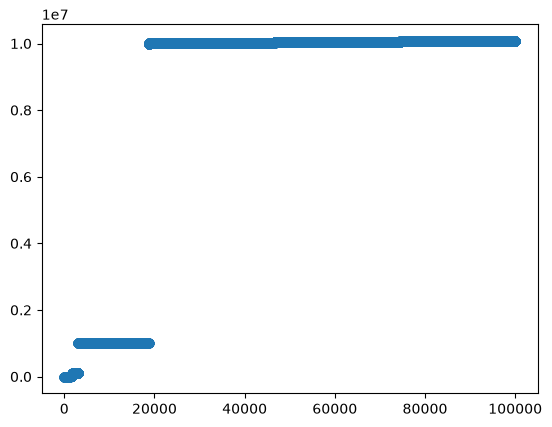

In [4]:
plt.scatter(range(100000), data_sentiment["message_id"][:100000])

In [5]:
data_sentiment.describe(include='all')

,message_id,user_id,created_at,sentiment,parent_message_id,in_reply_to_message_id,symbol_list,timestamp
count,2058472.0,2058472.0,2058472,566254,1092176.0,835777.0,2058472,2.058472e+06
unique,2058472.0,2058472.0,NaN,2,261237.0,624206.0,51780,NaN
top,4.0,4.0,NaN,Bullish,101195691.0,101176220.0,[],NaN
freq,1.0,1.0,NaN,487032,1050.0,446.0,940202,NaN
mean,NaN,NaN,2017-05-04 20:46:23.850244+00:00,NaN,NaN,NaN,NaN,1.493930e+06
min,NaN,NaN,2008-05-27 15:28:28+00:00,NaN,NaN,NaN,NaN,1.211902e+06
25%,NaN,NaN,2017-11-06 19:33:42+00:00,NaN,NaN,NaN,NaN,1.509996e+06
50%,NaN,NaN,2017-11-09 19:17:08.500000+00:00,NaN,NaN,NaN,NaN,1.510255e+06
75%,NaN,NaN,2017-11-14 17:34:31+00:00,NaN,NaN,NaN,NaN,1.510680e+06
max,NaN,NaN,2017-11-17 23:47:53+00:00,NaN,NaN,NaN,NaN,1.510962e+06


#### Data message body

In [6]:
num = 0
folder = "messages"

data_message_body = load_csv(number=num, folder=folder, dtype={"message_id": str})
data_message_body = message_id_cleaning(data_message_body)
data_message_body = message_id_unique(data_message_body)
data_message_body["message_id"] = data_message_body["message_id"].astype("category")

print(data_message_body.info())
data_message_body.head()

folder : messages
matricule : 000
path : /home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/data/messages/msg_000.csv
<class 'pandas.DataFrame'>
Index: 3125805 entries, 0 to 3263003
Data columns (total 2 columns):
 #   Column        Dtype   
---  ------        -----   
 0   message_id    category
 1   message_body  str     
dtypes: category(1), str(1)
memory usage: 83.5 MB
None


,message_id,message_body
0,4,"Sorry, I mean trading $V ;)"
1,5,Following HEK ($HEK for stocktweets) this morn...
2,6,Wondering when the $AAPL rocket is going to ta...
3,7,Welcome early adopters! Remember to prefix the...
4,9,My $AAPL puts are now barely profitable. I st...


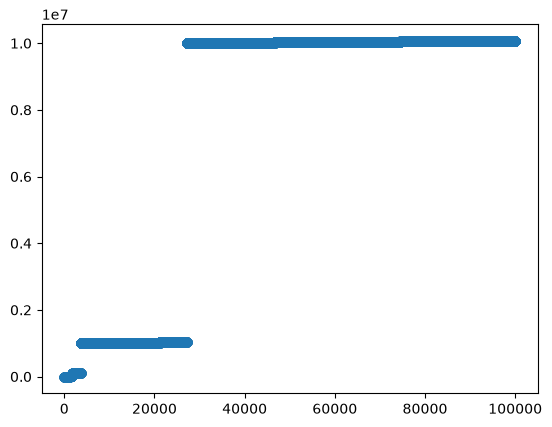

In [7]:
plt.scatter(range(100000), data_message_body["message_id"][:100000])

In [8]:
data_message_body.describe()

,message_id,message_body
count,3125805,3125805
unique,3125805,3040673
top,4,$TOPS
freq,1,1386


#### Data merged

In [9]:
data = pd.merge(data_message_body, data_sentiment[["message_id", "created_at", "timestamp", "sentiment"]], on="message_id", how="inner")
data.dropna(subset=["sentiment"], inplace=True)
data["sentiment_01"] = (data["sentiment"]=="Bullish")*1
data["sentiment_01"] = data["sentiment_01"].astype("category")
data["message_id"] = data["message_id"].astype("category")
del data_message_body
del data_sentiment

print(data.info())
data.head()

<class 'pandas.DataFrame'>
Index: 566254 entries, 18756 to 2058469
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   message_id    566254 non-null  category           
 1   message_body  566254 non-null  str                
 2   created_at    566254 non-null  datetime64[us, UTC]
 3   timestamp     566254 non-null  int64              
 4   sentiment     566254 non-null  str                
 5   sentiment_01  566254 non-null  category           
dtypes: category(2), datetime64[us, UTC](1), int64(1), str(2)
memory usage: 28.6 MB
None


,message_id,message_body,created_at,timestamp,sentiment,sentiment_01
18756,10000059,@Lucardes 759.63M x $2 = $1.5bn valuation $ZNG...,2012-10-15 18:57:06+00:00,1350327,Bearish,0
18767,10000071,$FVI Silver juniors are undervalued dispite th...,2012-10-15 18:57:38+00:00,1350327,Bullish,1
18768,10000072,$GS GS will have good earning too. C and JPM w...,2012-10-15 18:57:39+00:00,1350327,Bullish,1
18779,10000084,$WYNN - we are in the calls big this is why : ...,2012-10-15 18:58:20+00:00,1350327,Bullish,1
18782,10000088,$JPM GS will have good earning too. C and JPM...,2012-10-15 18:58:23+00:00,1350327,Bullish,1


message_id      0.0
message_body    0.0
created_at      0.0
timestamp       0.0
sentiment       0.0
sentiment_01    0.0
dtype: float64


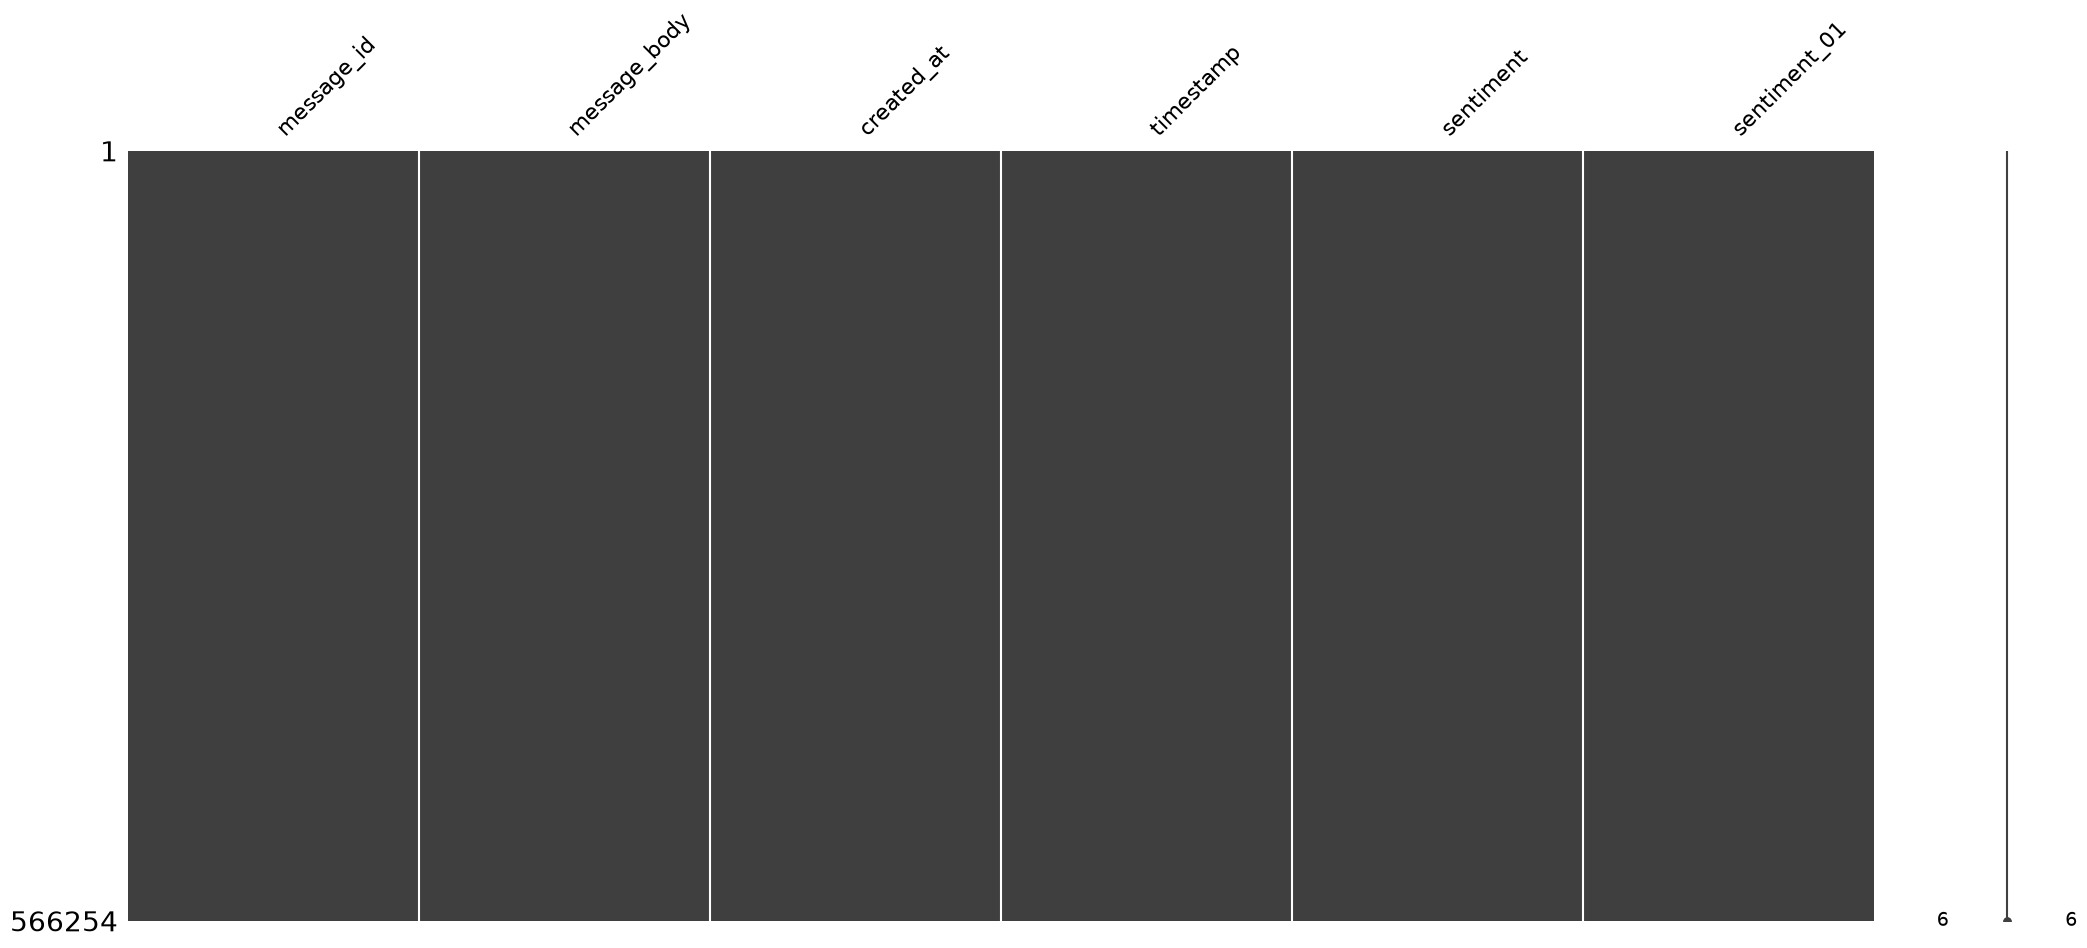

,message_id,message_body,created_at,timestamp,sentiment,sentiment_01
count,566254.0,566254,566254,5.662540e+05,566254,566254.0
unique,566254.0,546841,NaN,NaN,2,2.0
top,10000059.0,$TOPS,NaN,NaN,Bullish,1.0
freq,1.0,651,NaN,NaN,487032,487032.0
mean,NaN,NaN,2017-10-09 22:41:08.970447+00:00,1.507588e+06,NaN,NaN
min,NaN,NaN,2012-10-15 18:57:06+00:00,1.350327e+06,NaN,NaN
25%,NaN,NaN,2017-11-07 18:08:56+00:00,1.510078e+06,NaN,NaN
50%,NaN,NaN,2017-11-10 13:06:50+00:00,1.510319e+06,NaN,NaN
75%,NaN,NaN,2017-11-14 21:32:20.500000+00:00,1.510695e+06,NaN,NaN
max,NaN,NaN,2017-11-17 23:47:53+00:00,1.510962e+06,NaN,NaN


In [10]:
print(data.isna().mean()*100)
msno.matrix(data)
plt.show()
data.describe(include='all')

#### Data sampled and balanced or not

In [11]:
# Number of samples from data
N_samples = 10000

##### Data sample and unbalanced

In [12]:
# Data sampled
data_sample = data.sample(n=N_samples, random_state=42)

##### Data sampled and balanced

Attention au piège de l'échantillonnage 50/50 :

- En forçant artificiellement un équilibre 50/50 dans notre échantillon d'entraînement alors que notre grand jeu de données est très déséquilibré (par exemple 90% / 10%), cela aidera par la suite le modèle de regression logistique à bien apprendre à classer la classe minoritaire.

- Cependant, les probabilités prédites par notre modèle de régression logistique seront légèrement "biaisées" par rapport à la réalité du terrain (le modèle croira que le monde extérieur contient 50% de chaque classe). 

- Aussi un ajustement des seuils de décision ou un calibrage de probabilités pourra être envisagé par la suite.

In [13]:
# Number of samples for each class
N_samples_bearish = int(N_samples*0.5)
N_samples_bullish = N_samples - N_samples_bearish

# Split bullish data from bearish one
data_bearish = data[data["sentiment_01"] == 0]
data_bullish = data[data["sentiment_01"] == 1]

# Data sampled for each class
data_bearish_sample = data_bearish.sample(n=N_samples_bearish, random_state=42)
data_bullish_sample = data_bullish.sample(n=N_samples_bullish, random_state=42)
del data_bearish
del data_bullish

# Data sampled
data_sample = pd.concat([data_bearish_sample, data_bullish_sample])
data_sample = data_sample.sample(frac=1, random_state=42).reset_index( drop=True)
del data_bearish_sample
del data_bullish_sample

## II. Preprocessing

In [14]:
# Loading of english language model without parser & NER 
# (useless for Bow & TF-IDF cause they loser the words' order in documents)
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Tokenisation & lemmatisation (without cashtag gestion)
def spacy_tokenizer(text):
    doc = nlp(text)

    # We keep lemma, and drop punctuation & space cases
    tokens = [token.lemma_.lower() for token in doc if not token.is_punct and not token.is_space and not token.is_stop]

    return tokens

# Tokenisation & lemmatisation (with cashtag gestion)
def spacy_cashtag_tokenizer(text, ignore_cashtags=False):
    doc = nlp(text)
    tokens = []
    skip_next = False
    
    for i, token in enumerate(doc):
        if skip_next:
            skip_next = False
            continue

        # We deal with cashtag (ex "$AAPL")
        if token.text == '$' and i + 1 < len(doc) and doc[i+1].text.isalnum():
            if ignore_cashtags==False:
                # We merge the "$" & "X" (ex: "$aapl")
                cashtag = token.text + doc[i+1].text
                tokens.append(cashtag.lower())
            skip_next = True # to skip the next token

        # We keep lemma, and drop punctuation & space cases
        elif not token.is_punct and not token.is_space and not token.is_stop:
            tokens.append(token.lemma_.lower())
            
    return tokens

def plot_matrix(Matrix, vectorizer, log_scale=False, title="Matrix", doc_labels=None, n_words_max=30, n_docs_max=30, ax=None):

    vocabulary = vectorizer.get_feature_names_out()
    n_words = len(vocabulary)
    n_docs = Matrix.shape[0]
    if log_scale:
        norm = colors.SymLogNorm(linthresh=0.1, vmin=Matrix.min(), vmax=Matrix.max(), base=10)
    else :
        norm = None

    im = ax.imshow(Matrix,
                   aspect="auto", 
                   cmap="viridis",
                   norm=norm
                   )
    ax.set_xlabel("Vocabuary")
    ax.set_ylabel("Documents")
    ax.set_title(title)

    if n_words <= n_words_max :
        ax.set_xticks(np.arange(n_words))
        ax.set_xticklabels(vocabulary, rotation=45, ha="right", fontsize=10)

    if n_docs<=n_docs_max :
        if doc_labels is None :
            doc_labels = [f"Doc {i}" for i in range(n_docs)]
        ax.set_yticks(np.arange(n_docs))
        ax.set_yticklabels(doc_labels, fontsize=10)

    return im

## III. Bag of Words (BoW)

If we consider the set of all the words appearing in our $T$ training documents, which we note $V$ (the **vocabulary**), we can create an index, which is a bijection associating to each $w$ word an integer, which will be its position in $V$.

Thus, for a document extracted from a set of documents containing $|V|$ different words, a BoW representation will be a vector of size $|V|$, whose value at the index of a word $w$ will be its number of occurrences in the document.

The next function takes as input a list of documents (again, each in the form of a string) and returns:
- A vocabulary that associates, to each word encountered, an index
- A matrix, with rows representing documents and columns representing words indexed by the vocabulary. In position $(i,j)$, one should have the number of occurrences of the word $j$ in the document $i$.

In [15]:
# Create Bag of words matrix from messages's bodies of data sample
vectorizer_bow = CountVectorizer(tokenizer=lambda text: spacy_cashtag_tokenizer(text, ignore_cashtags=True), token_pattern=None)
Bow = vectorizer_bow.fit_transform(data_sample["message_body"]).toarray()
voc_bow = vectorizer_bow.vocabulary_
print('Bag of Word matrix :\n', Bow)
print('Bag of Word matrix shape :', Bow.shape)
print('Bag of Word matrix min :', Bow.min(), 'Bag of Word matrix max :', Bow.max())
print('vocabulary :', voc_bow)

if len(data_sample)<1000:
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    im = plot_matrix(Bow, vectorizer_bow, log_scale=True, title="Bag of Words matrix", ax=ax)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Frequency")
    plt.tight_layout()
    plt.show()

Bag of Word matrix :
 [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Bag of Word matrix shape : (10000, 13431)
Bag of Word matrix min : 0 Bag of Word matrix max : 115
vocabulary : {'hold': 7900, 'line': 9086, 'not': 9779, '3': 1086, 'away': 5144, 'mate': 9328, 'sound': 11723, 'er': 6932, 'financial': 7222, '@spikenyc11': 4101, 'i&#39;m': 8467, 'cytr': 6296, 'lolololol': 9155, 'high': 7848, 'rate': 10850, 'low': 9194, 'mortgage': 9562, 'deduct': 6407, '=': 1779, 'stock': 11878, 'price': 10451, 'homebuilder': 7915, 'etc': 6951, 'profit': 10494, 'sell': 11381, 'strong': 11930, 'likelihood': 9078, 'redesign': 10923, 'application': 4991, 'disruptive': 6592, 'business': 5638, 'short': 11509, 'term': 12178, 'snap': 11651, 'warn': 12830, 'ride': 11097, 'believe': 5311, 'great': 7630, 'sale': 11247, 'announcement': 4956, 'rep': 10991, 'hiring&#39;s': 7870, 'possibly': 10374, 'merger': 9396, '$': 1, 'btc.x': 5580, 'tell': 1

reverse vocabulary vector : {7900: 'hold', 9086: 'line', 9779: 'not', 1086: '3', 5144: 'away', 9328: 'mate', 11723: 'sound', 6932: 'er', 7222: 'financial', 4101: '@spikenyc11', 8467: 'i&#39;m', 6296: 'cytr', 9155: 'lolololol', 7848: 'high', 10850: 'rate', 9194: 'low', 9562: 'mortgage', 6407: 'deduct', 1779: '=', 11878: 'stock', 10451: 'price', 7915: 'homebuilder', 6951: 'etc', 10494: 'profit', 11381: 'sell', 11930: 'strong', 9078: 'likelihood', 10923: 'redesign', 4991: 'application', 6592: 'disruptive', 5638: 'business', 11509: 'short', 12178: 'term', 11651: 'snap', 12830: 'warn', 11097: 'ride', 5311: 'believe', 7630: 'great', 11247: 'sale', 4956: 'announcement', 10991: 'rep', 7870: 'hiring&#39;s', 10374: 'possibly', 9396: 'merger', 1: '$', 5580: 'btc.x', 12162: 'tell', 13162: 'y’', 6145: 'correction', 4130: '@steven0424', 6056: 'confirm', 5754: 'cc', 4897: 'amazon', 10476: 'probably', 5648: 'buy', 7035: 'expand', 5138: 'aw', 7603: 'govcloud', 8614: 'infrastructure', 10415: 'predictabl

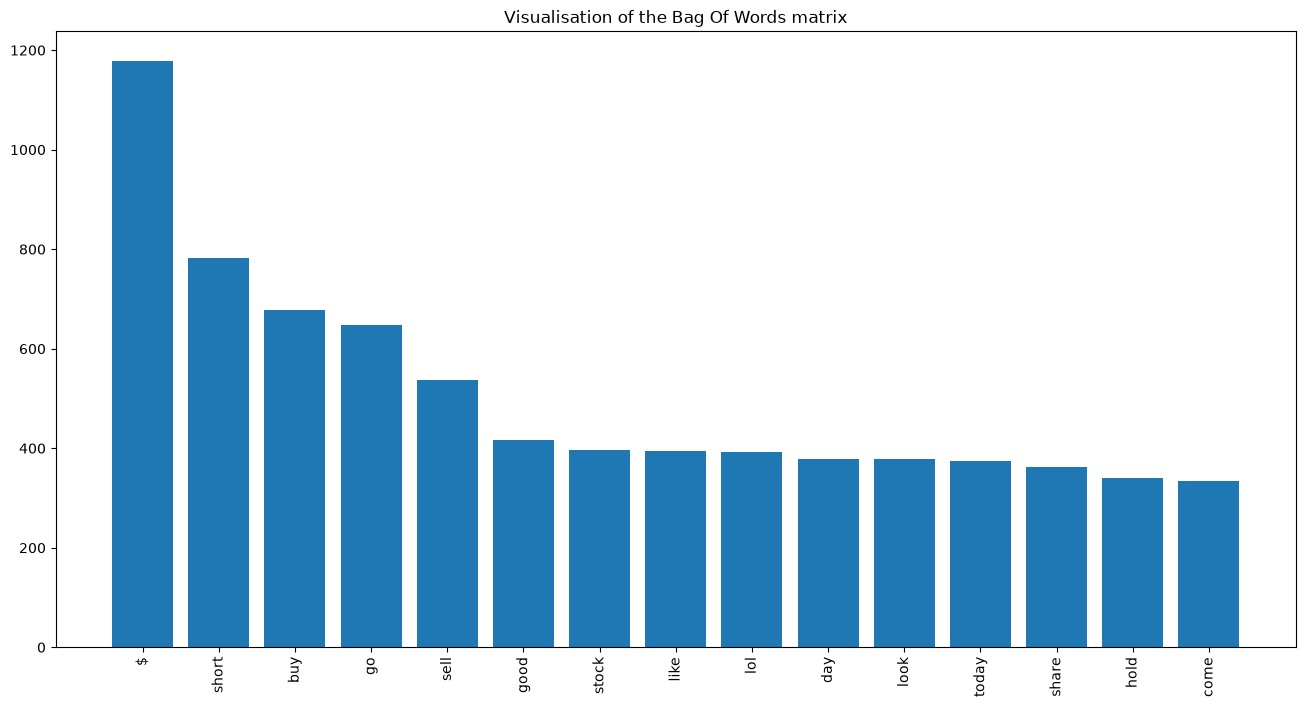

In [16]:
frequency = np.sum(Bow, axis=0)
rev_voc = {index: word for word, index in voc_bow.items()}
top_word = rev_voc[np.argmax(frequency)]
top_words = [rev_voc[index] for index in np.argsort(frequency)] # Use the function np.argsort; look into the documentation !
top_words_frequency = np.sort(frequency).astype(int)
print('reverse vocabulary vector :', rev_voc)
print('top words :', top_words)
print('top words frequency:', top_words_frequency)
print(f"most frequent word : \'{top_word}\'")

fig, ax = plt.subplots(figsize=(16,8))
top= np.minimum(15, len(voc_bow))
ax.bar(range(top), top_words_frequency[:-(top+1):-1])
ax.set_xticks(range(top))
ax.set_xticklabels(top_words[:-(top+1):-1], rotation='vertical')
plt.title("Visualisation of the Bag Of Words matrix")
plt.show()

## IV. TF-IDF

This is the product of the frequency of the term (TF) and its inverse frequency in documents (IDF).
This method is usually used to measure the importance of a term $i$ in a document $j$ relative to the rest of the corpus, from a matrix of occurrences $ words \times documents$. Thus, for a matrix $\mathbf{T}$ of $|V|$ terms and $D$ documents:
$$\text{TF}(T, w, d) = \frac{T_{w,d}}{\sum_{w'=1}^{|V|} T_{w',d}} $$

$$\text{IDF}(T, w) = \log\left(\frac{D}{|\{d : T_{w,d} > 0\}|}\right)$$

$$\text{TF-IDF}(T, w, d) = \text{TF}(X, w, d) \cdot \text{IDF}(T, w)$$

TF-IDF is generally better suited to low-density matrices, since it will penalize terms that appear in a large part of the documents.

In [18]:
# Create TF-IDF matrix from messages's bodies of data sample
vectorizer_tfidf = TfidfVectorizer(tokenizer=lambda text: spacy_cashtag_tokenizer(text, ignore_cashtags=True), token_pattern=None)

Tfidf = vectorizer_tfidf.fit_transform(data_sample["message_body"]).toarray()
voc_tfidf = vectorizer_tfidf.vocabulary_
print('TF-IDF matrix :\n', Tfidf)
print('TF-IDF matrix shape :', Tfidf.shape)
print('TF-IDF matrix min :', Tfidf.min(), 'Bag of Word matrix max :', Tfidf.max())
print('vocabulary :', voc_tfidf)

if len(data_sample)<1000:
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    im = plot_matrix(Tfidf, vectorizer_tfidf, log_scale=True, title="TF-IDF matrix", ax=ax)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Frequency")
    plt.tight_layout()
    plt.show()

TF-IDF matrix :
 [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
TF-IDF matrix shape : (10000, 13431)
TF-IDF matrix min : 0.0 Bag of Word matrix max : 1.0
vocabulary : {'hold': 7900, 'line': 9086, 'not': 9779, '3': 1086, 'away': 5144, 'mate': 9328, 'sound': 11723, 'er': 6932, 'financial': 7222, '@spikenyc11': 4101, 'i&#39;m': 8467, 'cytr': 6296, 'lolololol': 9155, 'high': 7848, 'rate': 10850, 'low': 9194, 'mortgage': 9562, 'deduct': 6407, '=': 1779, 'stock': 11878, 'price': 10451, 'homebuilder': 7915, 'etc': 6951, 'profit': 10494, 'sell': 11381, 'strong': 11930, 'likelihood': 9078, 'redesign': 10923, 'application': 4991, 'disruptive': 6592, 'business': 5638, 'short': 11509, 'term': 12178, 'snap': 11651, 'warn': 12830, 'ride': 11097, 'believe': 5311, 'great': 7630, 'sale': 11247, 'announcement': 4956, 'rep': 10991, 'hiring&#39;s': 7870, 'possibly': 10374, 'merger': 9396, '$': 1, '

# Prediction of Stocktwits messages sentiments

La régression logistique est un modèle possible pour classifier les sentiments des messages Stocktwits. L'avantage d'un tel modèle comparé à des modèles bien plus complexe dans leur architecture que sont les Transformers est l'explicabilité (XAI).

### Lectures' reminders

#### Rappel : interprétation des coefficients d'un modèle de régressions logistique

Les coefficients de la régression logistique sont les paramètres permettant de modéliser le logarithme népérien des cotes (log-odds $ \text{Logit}(p) = \ln\left(\frac{p}{1 - p}\right) $) construites à partir des probabilités $p$ et $1-p$ d'appartenir à une classe ou l'autre.
$$
\ln\left(\frac{p}{1 - p}\right) = \hat\beta_0 + \hat\beta_1 \cdot x_1 + \hat\beta_2 \cdot x_2 + \dots \hat\beta_d \cdot x_d = X \cdot \hat\beta
$$

On rappelle qu'une cote (Odds ratio) peut être déterminée comme le ratio entre la probabilité de deux événements complémentaires d'un univers probabiliste $\omega$ :
$$
\text{Cote} = \frac{P(A)}{1-P(A)}
$$

En partant de la probabilité $p$ d'appartenir à une classe donnée, en passant par sa cote, on va pouvoir retourner à l'équation linéaire $ X \cdot \hat\beta $ et ainsi rendre l'interprétation des coefficients $ \hat\beta_i,\: \forall \llbracket 0, d \rrbracket $ intuitive.

##### $ p = P(y=1 \vert{} x) $

Soit $p$ la probabilité sachant une variable X donné que l'événement appartient à la classe 1 se produise :
$$
p = P(y=1 \vert{} x)
$$
Et par conséquent, la probabilité que cet événement ne se produise (la classe 0) est :
$$
1 - p = P(y=0 \vert{} x)
$$

##### Le problème de la non-linéarité

Si l'on cherche à exprimer directement la probabilité $p$ sous forme d'une combinaison linéaire simple des variables ($w_1 x_1 + b$), on se heurte à un mur mathématique :

- La combinaison linéaire peut valoir n'importe quel nombre réel de $-\infty$ à $+\infty$.
- La probabilité $p$, elle, est strictement coincée entre $0$ et $1$.

Il faut donc trouver une fonction mathématique qui sert de pont entre l'intervalle $[0, 1]$ (pour la probabilité) et l'intervalle $[-\infty, +\infty]$ (pour la combinaison linéaire). 

C'est là qu'interviennent les étapes de transformation.

##### Passer des probabilités aux cotes (Odds)

$$
\text{Cote} = \frac{p}{1 - p}
$$

- Nouvel intervalle : Si $p$ varie de $0$ à $1$, la cote varie de $0$ à $+\infty$.
    
On a résolu la borne supérieure (plus de limite à $1$), mais la borne inférieure est toujours bloquée à $0$ (pas de nombres négatifs).

##### Passer des cotes aux logarithmes népériens des cotes (Log-Odds)

$$
\text{Logit}(p) = \ln\left(\frac{p}{1 - p}\right)
$$

- Nouvel intervalle : Si la cote varie de $0$ à $+\infty$., le log-odds (ou log-côte) peut prendre n'importe quelle valeur réelle de $-\infty$ à $+\infty$.

##### Exhibition de l'équation linéaire présente dans le modèle de regression logistique

C'est précisément cette quantité, le log-odds, que la régression logistique choisit d'égaler à une combinaison linéaire des variables explicatives X avec les coefficients $\hat\beta$ :
$$
\text{Logit}(p) = \ln\left(\frac{p}{1 - p}\right) = \hat\beta_0 + \hat\beta_1 \cdot x_1 + \hat\beta_2 \cdot x_2 + \dots \hat\beta_d \cdot x_d = X \cdot \hat\beta
$$

Aussi les cotes des probabilités $ p = P(y=1 \vert{} x) $ s'expriment en fonction des coefficients $ \hat\beta $ telles que :
$$
\begin{align*}
\frac{p}{1 - p} &= \exp\left( \hat\beta_0 + \hat\beta_1 \cdot x_1 + \hat\beta_2 \cdot x_2 + \dots \hat\beta_d \cdot x_d \right) &&= \exp\left( X \cdot \hat\beta \right) \\
\frac{p}{1 - p} &= \exp\left( \hat\beta_0 \right) \cdot \exp\left( \hat\beta_1 \cdot x_1 \right) \cdot \exp\left( \hat\beta_2 \cdot x_2 \right) \dots \exp\left( \hat\beta_d \cdot x_d \right) \\
\frac{p}{1 - p} &= \exp\left( \hat\beta_0 \right) \cdot \exp\left( \hat\beta_1 \right)^{x_1} \cdot \exp\left( \hat\beta_2 \right)^{x_2} \dots \exp\left( \hat\beta_d \right)^{x_d}
\end{align*}
$$

##### Interprétation des coefficient $\hat\beta$ du modèle de régression logistique

- Si l'Odds Ratio est > 1 (ex: 2) : Chaque augmentation de $1$ unité de la variable explicative multiplie les cotes (ex : double les chances de succès).
- Si l'Odds Ratio est < 1 (ex: 0.5) : Chaque augmentation de $1$ unité de la variable explicative divise les cotes par 2 (ex : réduit de moitié les chances de succès).
- Si l'Odds Ratio est = 1 (donc coefficient = 0) : La variable n'a aucun impact sur la prédiction.

#### Rappel : Matrice de Confusion

La matrice de confusion est un outil de visualisation permet dévaluer la performance d'un modèle de classification binaire (ou multi-classes). Ainsi, elle compare les prédictions d'un modèle avec les vraies valeurs de la vérité terrain (grownd truth)).

1. Définition des concepts fondamentaux

Pour un problème de classification binaire (classes: Positif (1) / Négatif (0)), la matrice croise les prédictions du modèle avec la réalité :

- Vrai Positif ($TP$) : Le modèle a prédit Positif, et la vérité terrain est Positive.
- Vrai Négatif ($TN$) : Le modèle a prédit Négatif, et la vérité terrain est Négative.
- Faux Positif ($FP$) : Le modèle a prédit Positif, mais la vérité terrain est Négative. (Erreur de Type I)
- Faux Négatif ($FN$) : Le modèle a prédit Négatif, mais la vérité terrain est Positive. (Erreur de Type II) 

                           ┌──────────────────┬──────────────────┐
                           │    Positif (1)   │    Négatif (0)   │
        ┌──────────────────┼──────────────────┼──────────────────┤
        │  Prédiction      │   Vrai Positif   │   Faux Positif   │
        │  Positif (1)     │      (VP)        │      (FP)        │
        │  (Predicted)     │ (Bonne prévision)│ (Erreur Type I)  │
        ├──────────────────┼──────────────────┼──────────────────┤
        │  Prédiction      │   Faux Négatif   │   Vrai Négatif   │
        │  Négatif (0)     │      (FN)        │      (VN)        │
        │  (Predicted)     │ (Erreur Type II) │ (Bonne prévision)│
        └──────────────────┴──────────────────┴──────────────────┘

#### Rappel : métrique F1-score

Le F1-score est une métrique correspondant à la moyenne harmonique de la précision et du rappel. A la différence d'une precision classique, elle à la particularité de pénaliser correctement les résultats obtenus pour des modèles entrainés sur des jeux de données déséquilibrés. 

##### 1. La formule mathématique

$$
F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$

##### 2. Les composantes de la formule

Le F1-score, est la moyenne harmonique, autrement dit le produit de 2 sous-score que sont :

- La Précision (Precision) :

    Définition : Parmi toutes les prédictions positives faites par le modèle, quelle proportion était réellement correcte ? (Mesure la capacité à éviter les faux positifs).
    $$
    \text{Precision} = \frac{TP}{TP + FP}
    $$

- Le Rappel/Sensibilité (Recall) :

    Définition : Parmi tous les vrais exemples positifs présents dans le jeu de données, quelle proportion le modèle a-t-il réussi à détecter ? (Mesure la capacité à ne rien rater).
    $$
    \text{Recall} = \frac{TP}{TP + FN}
    $$

(Où TP = Vrais Positifs, FP = Faux Positifs, FN = Faux Négatifs).

Bonus :

- Exactitude (Accuracy) : 
    Définition : Proportion globale de prédictions correctes.
    $$
    \text{Accuracy} = \frac{VP + VN}{VP + VN + FP + FN}
    $$

##### 3. Pourquoi utiliser une moyenne harmonique plutôt qu'une moyenne classique ?

- La moyenne harmonique a une propriété cruciale : elle pénalise fortement les valeurs extrêmes.

- Si l'un des deux indicateurs (la précision ou le rappel) est très mauvais (proche de 0), le F1-score s'effondrera, même si l'autre indicateur est excellent (proche de 1).

Exemple : Un modèle qui aurait une précision de $1.0$ mais un rappel de $0.0$ aura un F1-score de $0.0$ (contrairement à une moyenne arithmétique qui donnerait 0.5). C'est pour cela qu'il s'agit d'un excellent juge de paix pour repérer les modèles "paresseux" qui trichent en ignorant une classe.

## Split of the dataset into datatrain/datatest

In [2]:
from sklearn.model_selection import train_test_split

Les données que nous utiliserons pour entrainer et tester notre modèle, sont composées de 100000 messages dont les sentiments ont été annotés manuellement. Elles ont été extraites aléatoirement des messages Stocktwits de telle manière à obtenir une répartition 50/50 entre les messages dont le sentiment est haussier et ceux dont le sentiment est baissier sans quoi notre classifieur était biaisé au point de prédire systématiquement le sentiment majoritaire (haussier) de notre jeu de données d'entrainement. Nous avons tokenisé et lemmatisé ces messages via spaCy. Le pipeline identifie les cashtags (ex. "$AAPL") et les ignorer (afin d'éviter à notre classifieur d'être biaisé par la tendance particulière d'une action sur le très long terme). Elle supprime aussi la ponctuation, les espaces et les mots vides, puis normalise chaque terme en minuscules et en lemme. 

La représentation que nous avons choisi est TF-IDF. Nous avons préféré celle-ci à word2vec, car sur des messages courts, les décisions se jouent souvent sur des termes précis. TF-IDF donnera un poids fort à ces mots, tandis que word2vec lui produira un vecteur moyennant la sémantique de chacun des mots d'un message. Aussi l'espace dense à 200 dimensions de word2vec ne permet pas la même explicabilité que le vocabulaire de TF-IDF. Nous avons aussi choisi d'inclure dans notre vocabulaire des bi-gram plutôt que seulement des simples mono-gram. Ainsi nous préservons la sémantique de certaine expression notamment. Cela augmente grandement la taille de notre vocabulaire, néanmoins pour contrer cette inflation, nous filtrons respectivement les termes trop rares et trop fréquents (les mots apparaissant moins de 5 fois dans notre corpus (trop rare), ainsi que les mots apparaissant plus 85 % dans notre corpus (trop commun) sont écartés du vocabulaire.).

### Data loading and sampling

In [3]:
import data_sample_loading_from_stocktwits as dload


#Loading Data
data = dload.data_loading()
# Data sampled
N_samples=80000
N_samples+=int(N_samples*0.25)
data_sample = dload.data_sampled(data, N_samples, ratio=0.5)
data_sample.describe(include='all')

folder : feature_wo_messages
matricule : 000
path : /home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/data/feature_wo_messages/feature_wo_messages_000.csv
folder : messages
matricule : 000
path : /home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/data/messages/msg_000.csv


,message_id,message_body,created_at,timestamp,sentiment,sentiment_01
count,100000.0,100000,100000,1.000000e+05,100000,100000.0
unique,100000.0,97853,NaN,NaN,2,2.0
top,10000059.0,$TOPS,NaN,NaN,Bullish,0.0
freq,1.0,124,NaN,NaN,50000,50000.0
mean,NaN,NaN,2017-09-28 12:21:56.904220+00:00,1.506601e+06,NaN,NaN
min,NaN,NaN,2012-10-15 18:57:06+00:00,1.350327e+06,NaN,NaN
25%,NaN,NaN,2017-11-07 19:05:52.750000+00:00,1.510081e+06,NaN,NaN
50%,NaN,NaN,2017-11-10 12:50:33.500000+00:00,1.510318e+06,NaN,NaN
75%,NaN,NaN,2017-11-14 20:56:49.250000+00:00,1.510693e+06,NaN,NaN
max,NaN,NaN,2017-11-17 23:47:51+00:00,1.510962e+06,NaN,NaN


### Data spliting train/test (80%/20%)

In [4]:
# Split train/test (80% / 20%)
data_train, data_test = train_test_split(data_sample, test_size=0.2, random_state=42)
print(f"Length of training dataset : {len(data_train)}")
print(f"Length of testing dataset : {len(data_test)}")

Length of training dataset : 80000
Length of testing dataset : 20000


### Data tokenisation and lemmatisation

In [5]:
import data_sample_tokenisation_lemmatisation as dpre  

# Create TF-IDF matrix from messages's bodies of data sample on the vocabulary belonging to data train
vectorizer_tfidf = TfidfVectorizer(tokenizer=lambda text: dpre.spacy_cashtag_tokenizer(text, ignore_cashtags=True), 
                                   token_pattern=None,
                                   ngram_range=(1, 2),
                                   min_df=5,
                                   max_df=0.85 #, max_features=10000
                                   )

X_train = vectorizer_tfidf.fit_transform(data_train["message_body"])
y_train = np.array(data_train["sentiment_01"])

X_test  = vectorizer_tfidf.transform(data_test["message_body"])
y_test  = np.array(data_test["sentiment_01"])

voc_tfidf = vectorizer_tfidf.vocabulary_
features_tfidf = vectorizer_tfidf.get_feature_names_out()
rev_voc_tfidf = dpre.rev_voc(voc_tfidf)

print("X_train :\n", X_train)
print(f"y_train = {y_train}")

X_train :
 <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 537617 stored elements and shape (80000, 16359)>
  Coords	Values
  (0, 9612)	0.2574082042497326
  (0, 3489)	0.39794259838895046
  (0, 1482)	0.29332755608917027
  (0, 7656)	0.3203889241222668
  (0, 14204)	0.4282235229784885
  (0, 7258)	0.44495440482588094
  (0, 1076)	0.45313660071202294
  (1, 471)	0.3956779051928627
  (1, 11034)	0.2366729446252419
  (1, 14943)	0.4074040101315054
  (1, 8319)	0.3980376103369503
  (1, 9991)	0.28272359620447673
  (1, 12810)	0.20559047275096068
  (1, 14737)	0.24801212468692374
  (1, 9998)	0.35637124202937354
  (1, 12880)	0.3902593950651125
  (2, 1583)	0.4285960319827009
  (2, 8606)	0.29876719701413107
  (2, 13741)	0.23587214567084683
  (2, 0)	0.15462933468631962
  (2, 189)	0.41415649628668066
  (2, 5351)	0.18602232037587668
  (2, 13475)	0.2648552615920352
  (2, 13742)	0.4173368023946048
  (2, 5427)	0.4439025566356613
  :	:
  (79998, 14003)	0.18462006266430664
  (79998, 8392)	0.259846175

## Logistic regression model to predict sentiment of Stocktwits messages

In [7]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score, accuracy_score

Nous avons testé plusieurs types de régularisations (ridge, lasso, elasticNet) afin d'améliorer les performances de notre régression logistique et celle qui obtient les meilleurs résultats et la régularisation elasticNet avec un F1-Score égale à $0.71$. (On retrouve le même résultat pour le F1-Score calculé par classe (bullish (1) et bearish (0)), ce qui est rassurant quant à la valeur du F1-Score global.) Grâce à cette régularisation, on constate que quasiment la moitié des mots de notre vocabulaire ($\approx 16000$), ne sont pas explicatifs (paramètres/Log odds ratio = 0). Ainsi l'on peut réduire notre vocabulaire à $\approx 8000$ mots. Dès lors qu'en est-il de cette liste et ce qu'elle nous apprend sur la nature de nos messages :

- Lorsque l’on observe les mots les plus explicatifs de notre régression pour bullish (correspondant aux paramètres/log odds ratio les plus grands de notre modèle) le champ lexical révèle une orientation très nettement haussière et spéculative. Présence marquée d'un vocabulaire d'expansion (explode, soar, accumulation, boom, runner) et d'incitations à l'achat (load, add, undervalue), renforcée par des émojis d'optimismes (🚀, 🐂, 💰) représentant la croissance. On retrouve aussi des consignes (don't sell, load, bear trap) pour maintenir la tendance à l'achat.

- Lorsque l’on observe les mots les plus explicatifs de notre régression pour bearish (correspondant aux paramètres/log odds les plus grands de notre modèle) la grande majorité des termes sont très négatifs pour disqualifier les actifs (garbage, trash, scam, trap fall, junk, disaster, terrible, dead). De même les émojis comme (🔻, 📉, ☠) représentant l'effondrement et la mort renforcent ce sentiment pessimiste. On retrouve aussi des consignes (add short, easy short, great short, hold short, sell signal) grandement orientées vers la vente à découvert.

En conclusion notre modèle de régression logistique comme classifieur du sentiment des messages Stocktwits représentés par TF-IDF, n'est peut-être pas le plus performant. Mais son explicabilité le rend intéressant lorsqu'il est question de se représenter la nature des messages les plus haussiers ou baissiers.

### Logistic regression (without regularization)

#### Solver without unbalanced class penalization

##### Model Training

In [7]:
# Training
model_Logreg_wo_reg_unbalanced = LogisticRegression(penalty=None)
model_Logreg_wo_reg_unbalanced.fit(X_train, y_train)

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (m

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects

##### Model evaluation

In [8]:
# Predictions & évaluation
y_pred = model_Logreg_wo_reg_unbalanced.predict(X_test)
print(f"Précision (Accuracy) : {accuracy_score(y_test, y_pred):.2f}")
print("\nRapport de classification :\n", classification_report(y_test, y_pred))
del y_pred

Précision (Accuracy) : 0.71

Rapport de classification :
               precision    recall  f1-score   support

           0       0.72      0.69      0.70      9922
           1       0.71      0.74      0.72     10078

    accuracy                           0.71     20000
   macro avg       0.71      0.71      0.71     20000
weighted avg       0.71      0.71      0.71     20000



#### Solver with unbalanced class penalization

##### Model Training

In [9]:
# Training
model_Logreg_wo_reg_balanced = LogisticRegression(penalty=None, class_weight='balanced')
model_Logreg_wo_reg_balanced.fit(X_train, y_train)

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (m

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

##### Model evaluation

In [10]:
# Predictions & évaluation
y_pred = model_Logreg_wo_reg_balanced.predict(X_test)
print(f"Précision (Accuracy) : {accuracy_score(y_test, y_pred):.2f}")
print("\nRapport de classification :\n", classification_report(y_test, y_pred))
del y_pred

Précision (Accuracy) : 0.71

Rapport de classification :
               precision    recall  f1-score   support

           0       0.73      0.68      0.70      9922
           1       0.70      0.75      0.72     10078

    accuracy                           0.71     20000
   macro avg       0.71      0.71      0.71     20000
weighted avg       0.71      0.71      0.71     20000



### Cross validation regularization l2 (ridge)

In [ ]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_ridge_cv = LogisticRegressionCV(Cs=Cs_range,
                                      cv=cv_stratifie,
                                      penalty='l2',
                                      scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                      max_iter=10000,
                                      random_state=42
                                      )

# Entraînement sur (X_train, y_train)
model_ridge_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_ridge_cv.C_[0]
best_lambda = 1.0 / best_C
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_ridge_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_ridge_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_ridge_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to 

Best C : 2.682696 (lambda: 0.372759)

Intercept (eta_0$) = 0.135498
Coefficients (eta$) : [ 0.60973285  0.29908921 -0.81958978 ...  0.25604572 -0.58438374
 -1.20812212]

F1-score : 0.746564
Accuracy : 0.734500

Rapport de classification complet :
              precision    recall  f1-score   support

           0       0.75      0.69      0.72      9922
           1       0.72      0.78      0.75     10078

    accuracy                           0.73     20000
   macro avg       0.74      0.73      0.73     20000
weighted avg       0.74      0.73      0.73     20000



,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),6869,3053
True : Bullish (1),2257,7821


### Cross validation regularization l1 (lasso)

In [10]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_lasso_cv = LogisticRegressionCV(Cs=Cs_range,
                                      cv=cv_stratifie,
                                      penalty='l1',
                                      solver='liblinear',
                                      scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                      max_iter=10000,
                                      random_state=42
                                      )

# Entraînement sur (X_train, y_train)
model_lasso_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_lasso_cv.C_[0]
best_lambda = 1.0 / best_C
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_lasso_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_lasso_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_lasso_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to 

Best C : 1.526418 (lambda: 0.655129)

Intercept (eta_0$) = 0.175077
Coefficients (eta$) : [ 0.78846449  0.19461114 -1.11505906 ...  0.          0.
 -1.98769078]

F1-score : 0.745705
Accuracy : 0.730600

Rapport de classification complet :
              precision    recall  f1-score   support

           0       0.76      0.68      0.71      9922
           1       0.71      0.78      0.75     10078

    accuracy                           0.73     20000
   macro avg       0.73      0.73      0.73     20000
weighted avg       0.73      0.73      0.73     20000



,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),6712,3210
True : Bullish (1),2178,7900


### Cross Validation ElasticNet

In [ ]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = [1] #np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_elasticNet_cv = LogisticRegressionCV(Cs=Cs_range,
                                           l1_ratios=[0.1, 0.3, 0.5, 0.7, 0.9],
                                           cv=cv_stratifie,
                                           penalty='elasticnet',
                                           solver='saga',
                                           scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                           max_iter=100,
                                           random_state=42
                                           )

# Entraînement sur (X_train, y_train)
model_elasticNet_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_elasticNet_cv.C_[0]
best_lambda = 1.0 / best_C
best_l1_ratio = model_elasticNet_cv.l1_ratio_[0]
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")
print(f"Best l1 ratio : {best_l1_ratio:.6f}")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_elasticNet_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_elasticNet_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_elasticNet_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, best_l1_ratio, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the ne

#### Model Training

In [8]:
# Training
model_Logreg_elasticNet = LogisticRegression(penalty='elasticnet', C=2.0, l1_ratio=0.60, solver='saga')
model_Logreg_elasticNet.fit(X_train, y_train)

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'elasticnet'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",2.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.6
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports

In [ ]:
# Training
model_Logreg_elasticNet = LogisticRegression(penalty='elasticnet', C=1.0, l1_ratio=0.5, solver='saga')
model_Logreg_elasticNet.fit(X_train, y_train)

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'elasticnet'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"C C: float, default=1.0Inverse of regularization str

#### Model Evaluation

In [9]:
# Predictions & évaluation
y_pred = model_Logreg_elasticNet.predict(X_test)
print(f"Précision (Accuracy) : {accuracy_score(y_test, y_pred):.2f}")
print("\nRapport de classification :\n", classification_report(y_test, y_pred))
del y_pred

Précision (Accuracy) : 0.73

Rapport de classification :
               precision    recall  f1-score   support

           0       0.75      0.69      0.72      9922
           1       0.72      0.78      0.75     10078

    accuracy                           0.73     20000
   macro avg       0.74      0.73      0.73     20000
weighted avg       0.74      0.73      0.73     20000



#### Model Analysis

In [10]:
# Coefficients of the logistic regression model
coefs_elasticNet = model_Logreg_elasticNet.coef_[0]

# Odds Ratios of coeficients
odds_elasticNet = np.exp(coefs_elasticNet)

coefs_odds = pd.DataFrame({'word' : features_tfidf, 
                           'coefficient' : coefs_elasticNet, 
                           'odd ratio' : odds_elasticNet
                           })
del coefs_elasticNet
del odds_elasticNet

coefs_odds

,word,coefficient,odd ratio
0,$,0.766862,2.153000
1,$ $,0.189860,1.209080
2,$ .50,-1.207163,0.299044
3,$ 0.00,-1.225987,0.293468
4,$ 0.02,0.000000,1.000000
...,...,...,...
16354,🥃,0.951152,2.588689
16355,🦄,0.594926,1.812896
16356,🦄 🦄,0.000000,1.000000
16357,🦈,-0.593221,0.552544


In [11]:
coefs_odds = coefs_odds.sort_values(by='coefficient', ascending=True)

coefs_odds

,word,coefficient,odd ratio
5960,dump,-6.928452,0.000980
5186,crash,-6.776888,0.001140
11687,put,-6.735065,0.001188
3559,bear flag,-6.452309,0.001577
12483,scam,-6.090027,0.002265
...,...,...,...
10289,nak,4.701267,110.086544
2432,@rahamon,4.746590,115.190807
15509,weak hand,4.880012,131.632239
8104,https://goo.gl/o2pxaj,7.550601,1901.886013


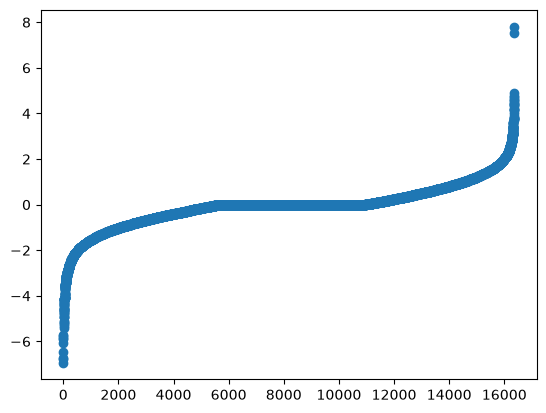

In [12]:
plt.scatter(range(len(coefs_odds)),coefs_odds['coefficient'])

In [13]:
coefs_odds_significant = coefs_odds[coefs_odds['coefficient'] != 0]

coefs_odds_significant

,word,coefficient,odd ratio
5960,dump,-6.928452,0.000980
5186,crash,-6.776888,0.001140
11687,put,-6.735065,0.001188
3559,bear flag,-6.452309,0.001577
12483,scam,-6.090027,0.002265
...,...,...,...
10289,nak,4.701267,110.086544
2432,@rahamon,4.746590,115.190807
15509,weak hand,4.880012,131.632239
8104,https://goo.gl/o2pxaj,7.550601,1901.886013


In [14]:
def func_test(df, 
              column, 
              ax, 
              percentile_inteval=[[0,25], [25,50], [50,75], [75,100]],
              colors = ['r', 'b', 'g', 'y']):
    len_new = 0
    df['percentile'] = df[column].apply(lambda x: percentileofscore(df[column], x))
    for i, interval in enumerate(percentile_inteval):
        df_subset = df[(df['percentile'] > interval[0]) & (df['percentile'] <= interval[1])][column]
        len_old = len_new
        len_new = len_old+len(df_subset)
        print(len_old, len_new)
        ax.scatter(np.arange(len_old, len_new), 
                   df_subset, 
                   color=colors[i], # Couleur de la palette Set1
                   alpha=0.5,        # Transparence pour voir les superpositions
                   )

0 2771
2771 5542
5542 8313
8313 11085


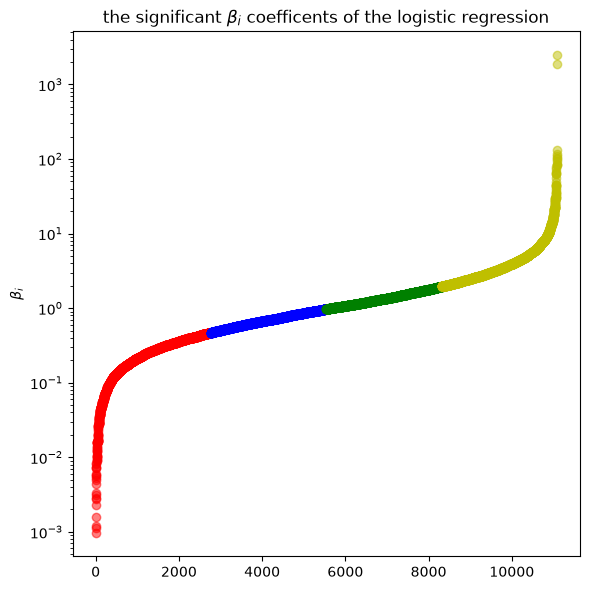

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
func_test(coefs_odds_significant, 'odd ratio', ax)
ax.set_yscale('log')
ax.set_ylabel(r'$\beta_i$')
ax.set_title(r'the significant $\beta_i$ coefficents of the logistic regression')
plt.tight_layout()
plt.show()

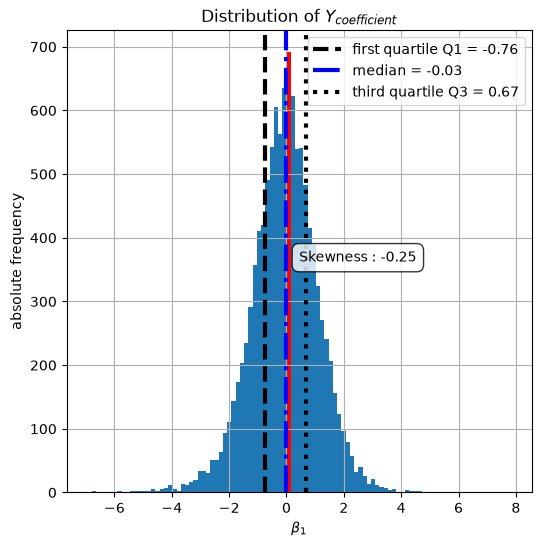

In [16]:
import stats_display as sd


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
sd.myhist(coefs_odds_significant, "coefficient", ax, r"$\beta_1$", bins=100)

In [17]:
def top_words_by_odds(df, column_A, column_B, top=10, ax=ax, ascending=False, log=True, verbose=False):
    top_df = df.sort_values(by='odd ratio', ascending=ascending).head(top)

    top_words = top_df[column_A].values
    if not ascending:
        top_odds = top_df[column_B].values
        ax.set_title(rf"Top {top} bullish Odd Ratios $\beta$")
    else:
        top_odds = 1/(top_df[column_B].values)
        ax.set_title(rf"Top {top} bearish Odd Ratios $\beta$")
    
    if verbose:
        print('top words :', top_words)
        print('top odds ratio:', top_odds)

    ax.bar(range(top), top_odds)
    ax.set_xticks(range(top))
    ax.set_xticklabels(top_words, rotation='vertical')
    ax.set_xlabel("Mots / Features")
    ax.set_ylabel("Odd Ratio")
    if log:
        ax.set_yscale('log')

top words : <ArrowStringArray>
['https://goo.gl/17jmbv', 'https://goo.gl/o2pxaj',             'weak hand',
              '@rahamon',                   'nak',                  'isrg',
                     '🚀',            'short trap',             'short try',
             'bear trap',                '@farne',             'bye short',
            'undervalue',                'shorty',            '@computec1',
          'accumulation',           'short cover',               'shortie',
              'high low',           'undervalued',                     '💰',
                  'soar',            'short burn',           '@mystic_mac',
 'https://goo.gl/yyqoci',                     '+',                 'sedor',
           'short screw',            'short lose',              'breakout',
              '@brianiq',          '@letterkenny',          'short attack',
               'explode',                   ':o)',                 'float',
                     '👌',              '@sthl129',       

/tmp/ipykernel_142671/2223153973.py:3: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_142671/2223153973.py:3: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_142671/2223153973.py:3: UserWarning: Glyph 128076 (\N{OK HAND SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Deja

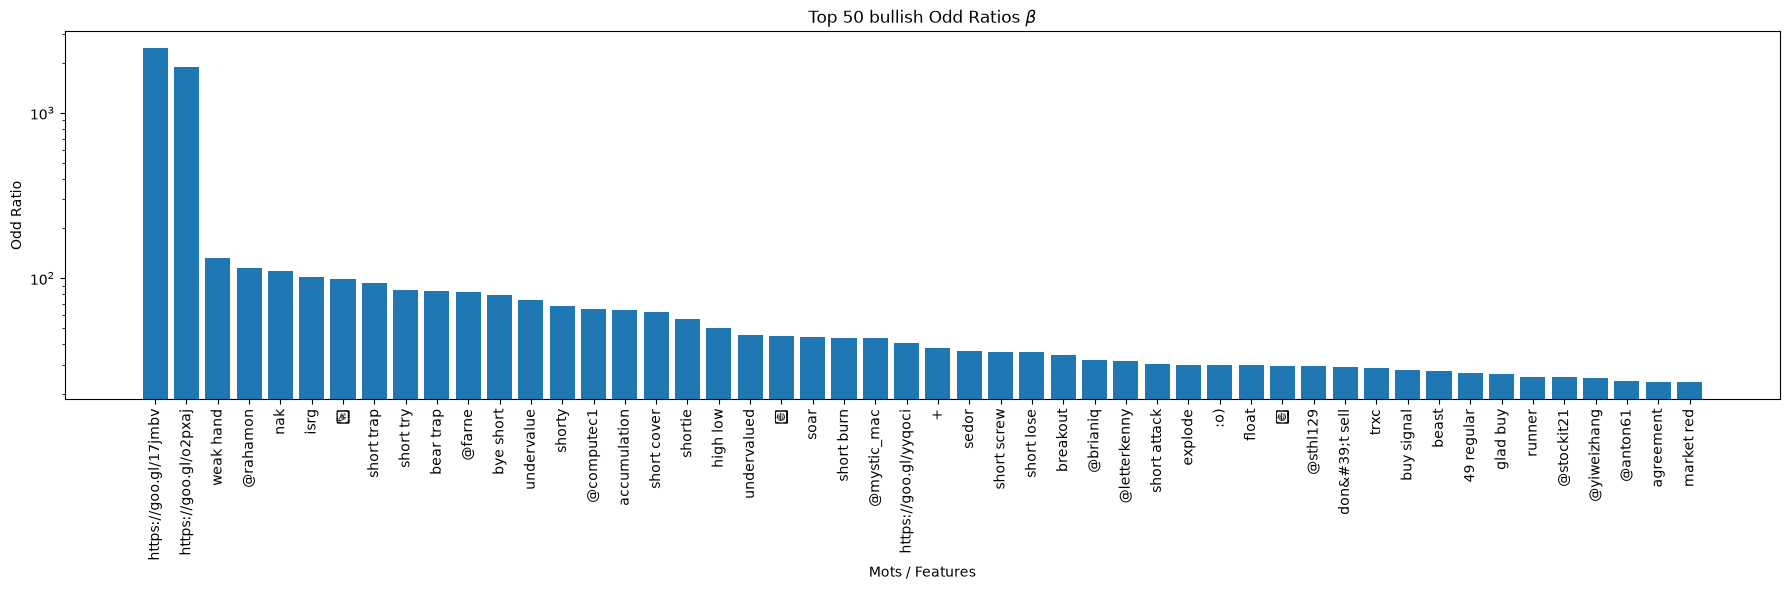

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(18, 6))
top_words_by_odds(coefs_odds_significant, 'word', 'odd ratio', top=50, ax=ax, ascending=False, verbose=True)
plt.tight_layout()
plt.show()

top words : <ArrowStringArray>
[         'dump',         'crash',           'put',     'bear flag',
          'scam',       'bearish',     'bagholder',       'garbage',
     'add short',          'warn',     'stay away',           'pos',
      'collapse',   'sell signal',          'sham',             '🔻',
      'disaster',             '📉',             '☠',         'trash',
          'junk',     'overvalue',     'downtrend',       '@tiago1',
    'easy short',       'buy put',   'great short',      '@snapftw',
          'trap',    'overbought',    'hold short',          'fall',
       'titanic',          'turd',  'single digit',          'poop',
        'baggie',        'pumper',      'terrible',          'dead',
 'i&#39;m short',          'musk',    'delusional',    '@wedgecake',
  'congrat bear',       'short $',      'eurozone',            'ge',
       'failure',     '@thebrain']
Length: 50, dtype: str
top odds ratio: [1020.91226849  877.33379315  841.39856478  634.16483893  441.43344

/tmp/ipykernel_142671/372038331.py:3: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_142671/372038331.py:3: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/Social-Media-as-Predictive-Information-for-Stock-Market/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


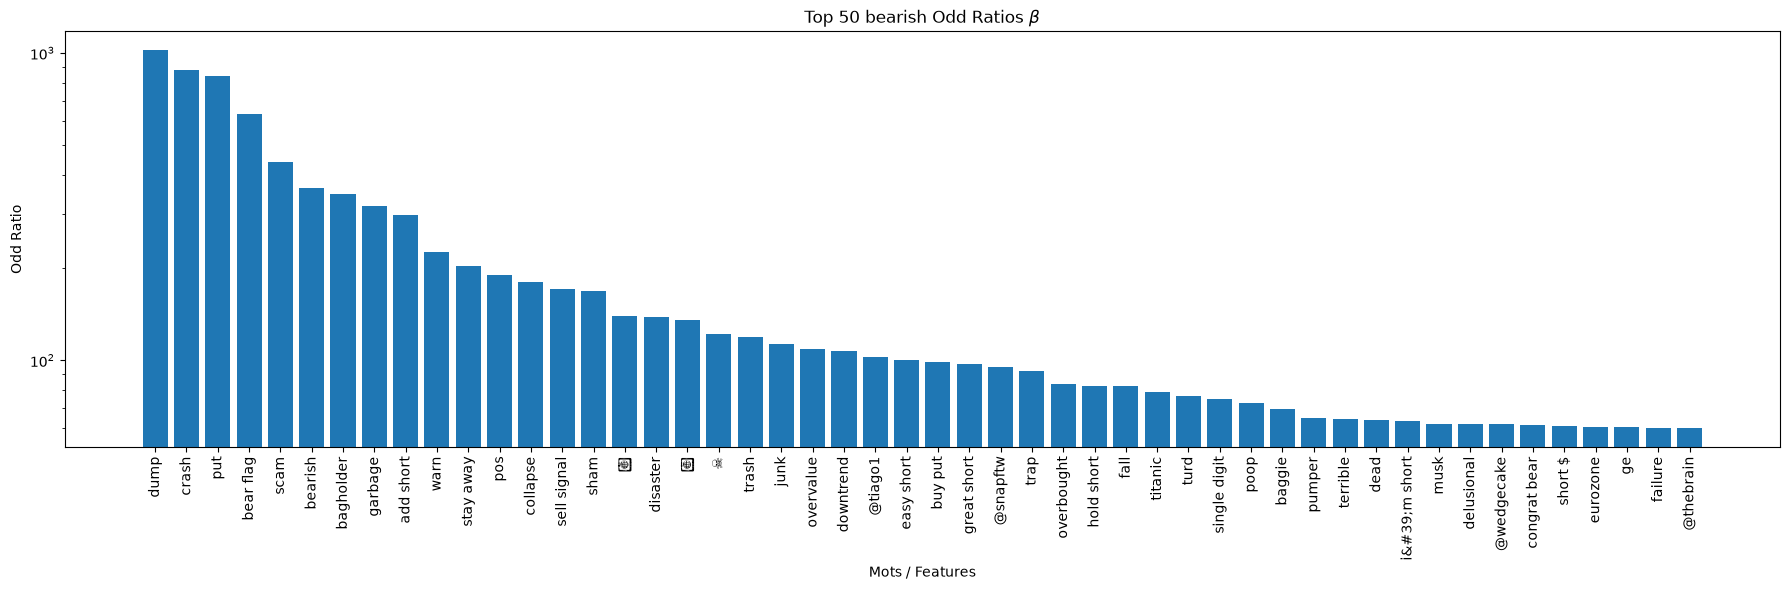

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(18, 6))
top_words_by_odds(coefs_odds_significant, 'word', 'odd ratio', top=50, ax=ax, ascending=True, verbose=True)
plt.tight_layout()
plt.show()

### Predictions with selective classification (3 classes)

On peut améliorer notre F1-Score en faisant le choix de sacrifier une certaine quantité de messages pour lesquelles on ne se prononcera pas. Ces messages correspondent à ceux dont la probabilité $0.25<P(y=1|x)<0.75$. On appelle ça une régression logistique par rejet d'incertitude. Ce choix est motivé par le fait que nos messages ne semblent pas linéairement séparables. Aussi plutôt que choisir une simple frontière linéaire, on choisit de définir une zone grise d’incertitude.

Ainsi, on obtient un F1-Score de 0.88. le prix à payer étant que l’on renonce à prédire 67 % de nos messages. Or au vu de la quantité de nos données, cela n’est peut-être pas tant problématique si notre objectif est d’évaluer sur le temps long terme l'évolution du cours d'une action.

#### Model Evaluation

In [20]:
#Prediction & evaluation
# P(y_i|x) = 1
probs_cl1 = model_Logreg_elasticNet.predict_proba(X_test)[:, 1]
# y_i \in {0, 1, 2}
y_pred_3cls = np.full(X_test.shape[0], 2, dtype=int)
y_pred_3cls[probs_cl1 < 0.25] = 0 # P(y_i|x) < 0.25
y_pred_3cls[probs_cl1 > 0.75] = 1 # P(y_i|x) > 0.75

# Filtrer of the confident predictions (0 ou 1)
confident_mask = (y_pred_3cls == 0) | (y_pred_3cls == 1)
y_test_confident = y_test[confident_mask]
y_pred_3cls_confident = y_pred_3cls[confident_mask]

print(f"Précision (Accuracy) : {accuracy_score(y_test_confident, y_pred_3cls_confident):.2f}")
nb_Uncertains = np.sum(y_pred_3cls == 2)
print(f"Number of uncertain predictions : {nb_Uncertains}")
print("\nRapport de classification :\n", classification_report(y_test_confident, y_pred_3cls_confident, 
                                                               labels=[0, 1], 
                                                               target_names=['Bearish', 'Bullish'], 
                                                               zero_division=0
                                                               ))

cm = confusion_matrix(y_test, y_pred_3cls, labels=[0, 1, 2])
cls_labels = ['Bearish (0)', 'Bullish (1)', 'Incertain (2)']
cm = pd.DataFrame(cm[:-1], 
                  index=[f"True : {name}" for name in cls_labels[:-1]], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )
del nb_Uncertains
del y_pred_3cls
del y_pred_3cls_confident
del cls_labels

cm


Précision (Accuracy) : 0.88
Number of uncertain predictions : 11131

Rapport de classification :
               precision    recall  f1-score   support

     Bearish       0.88      0.88      0.88      4600
     Bullish       0.87      0.88      0.87      4269

    accuracy                           0.88      8869
   macro avg       0.88      0.88      0.88      8869
weighted avg       0.88      0.88      0.88      8869



,Predicted : Bearish (0),Predicted : Bullish (1),Predicted : Incertain (2)
True : Bearish (0),4042,558,5322
True : Bullish (1),528,3741,5809
